# T32: drift-robust local comb solver
Regenerates the README figures. Inputs: `data/` (step-1 peaks, variant metrics, candidate subset from the harness) and the scorecard runs named in `analysis.py` (`runs/t32/sc/`, `benchmarks/baselines/*_v6w_tables`, `*_v7_tables`); the example panels read the FITS files in `data/smarts_dev`.

In [1]:
import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display
HERE = Path.cwd() if (Path.cwd() / 'analysis.py').exists() else Path('reports/2026-11-13_t32-local-drift')
sys.path.insert(0, str(HERE))
import analysis as A

## Step 1: residual vs peak index n
Gains drift linearly out of the frozen n·P0 windows; none→wrong stars are offset from n = 0 and scatter randomly.

{'gain_vertex': (29, 0.0527), 'none_to_wrong': (25, 0.0848), 'shared_correct': (59, 0.0304)}


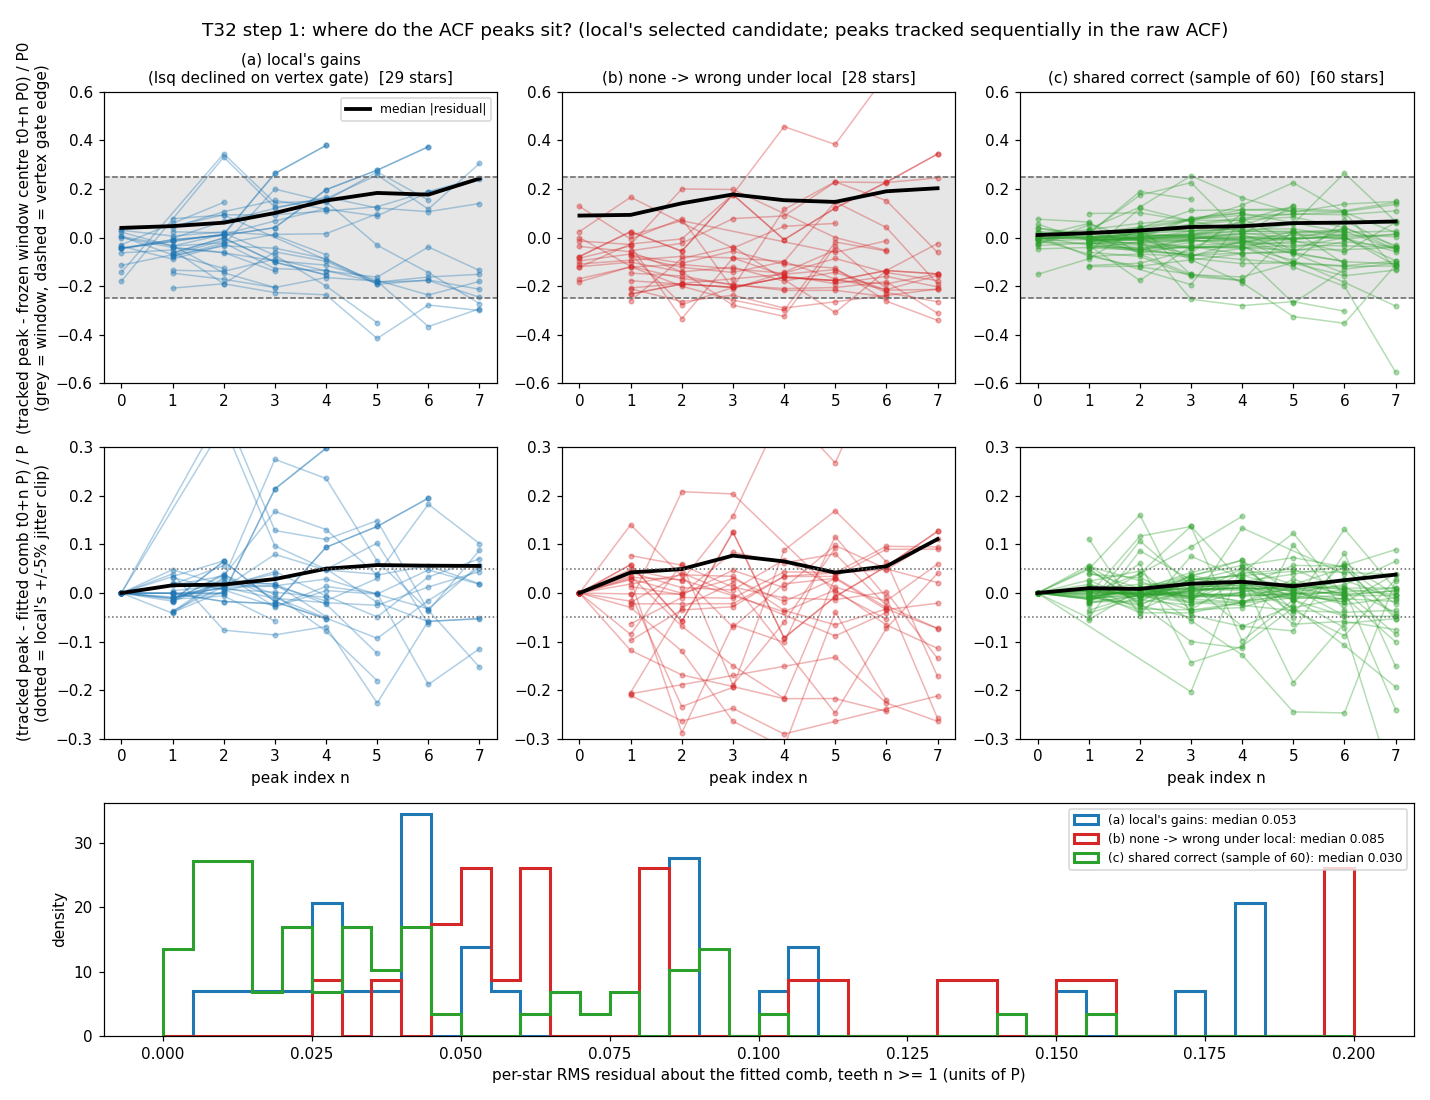

In [2]:
%run $HERE/fig_step1.py
display(Image(str(A.FIG / 'fig_step1_residual_vs_n.png')))

## Variant table and frontier
Rates per variant (dev_medium, both modes), serial timing on T12's 15 stars.

,variant,mode,success,wrong,precision,gained,lost,none_to_wrong,s_production
0,lsq,fullyear,0.251,0.088,0.711,0,0,0,1.417
1,lsq,assigned,0.147,0.055,0.697,0,0,0,1.079
2,local,fullyear,0.260,0.088,0.716,22,13,12,0.226
3,local,assigned,0.152,0.066,0.664,11,6,16,0.168
4,local_screen2,fullyear,0.251,0.088,0.711,0,0,0,0.688
5,local_screen2,assigned,0.147,0.055,0.697,0,0,0,0.624
6,local_track,fullyear,0.249,0.069,0.750,27,29,11,0.289
7,local_track,assigned,0.144,0.054,0.686,11,14,12,0.209
8,local_tol,fullyear,0.248,0.067,0.756,18,21,0,0.269
9,local_tol,assigned,0.145,0.048,0.711,7,9,4,0.217


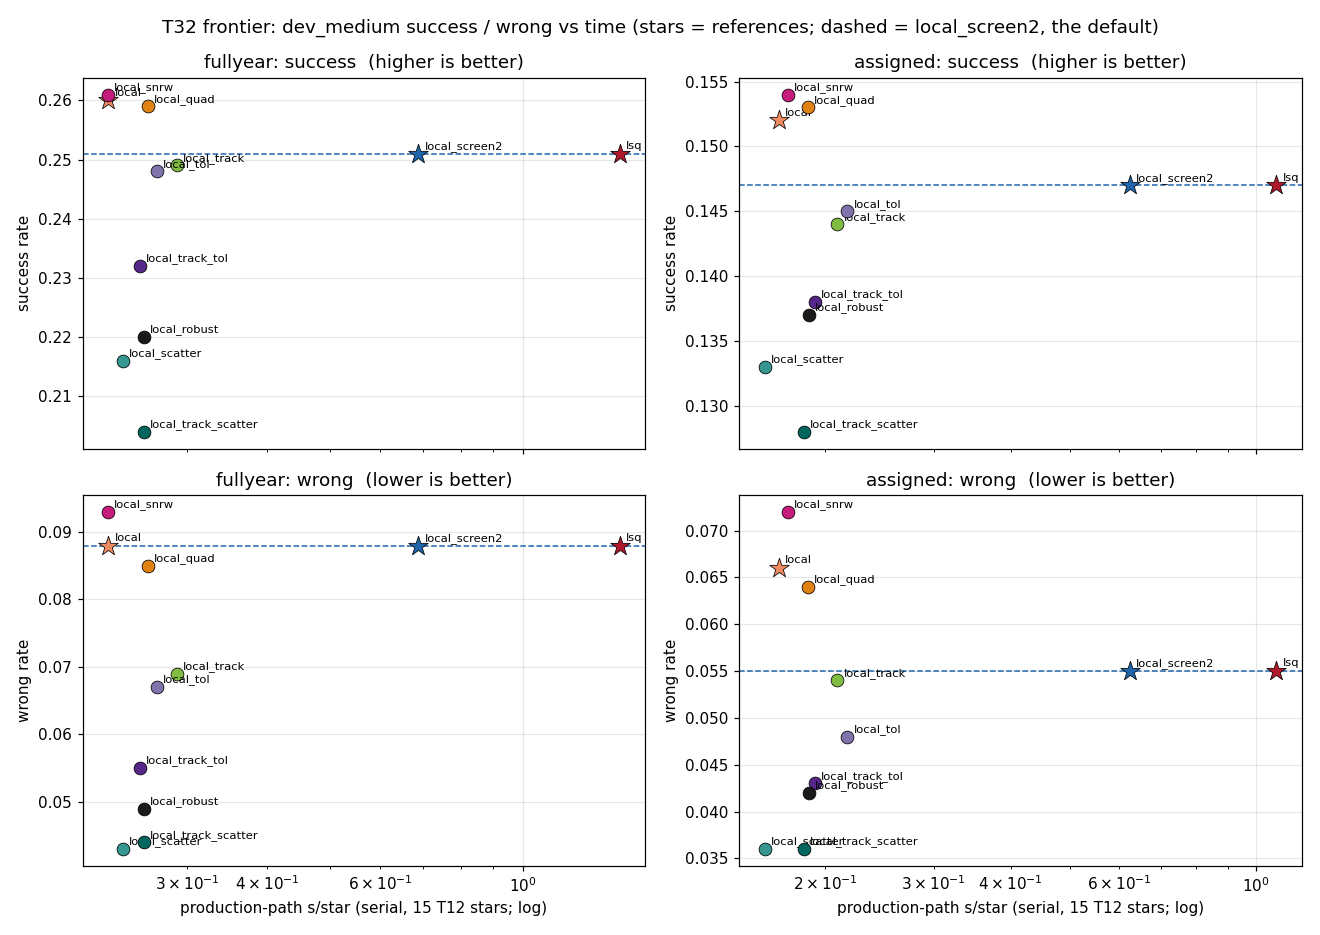

In [3]:
tab = pd.read_csv(A.DATA / 'variant_metrics.csv')
display(tab[['variant','mode','success','wrong','precision','gained','lost','none_to_wrong','s_production']].round(3))
A.fig_frontier(tab)
display(Image(str(A.FIG / 'fig_frontier.png')))

## Success and wrong by period bin

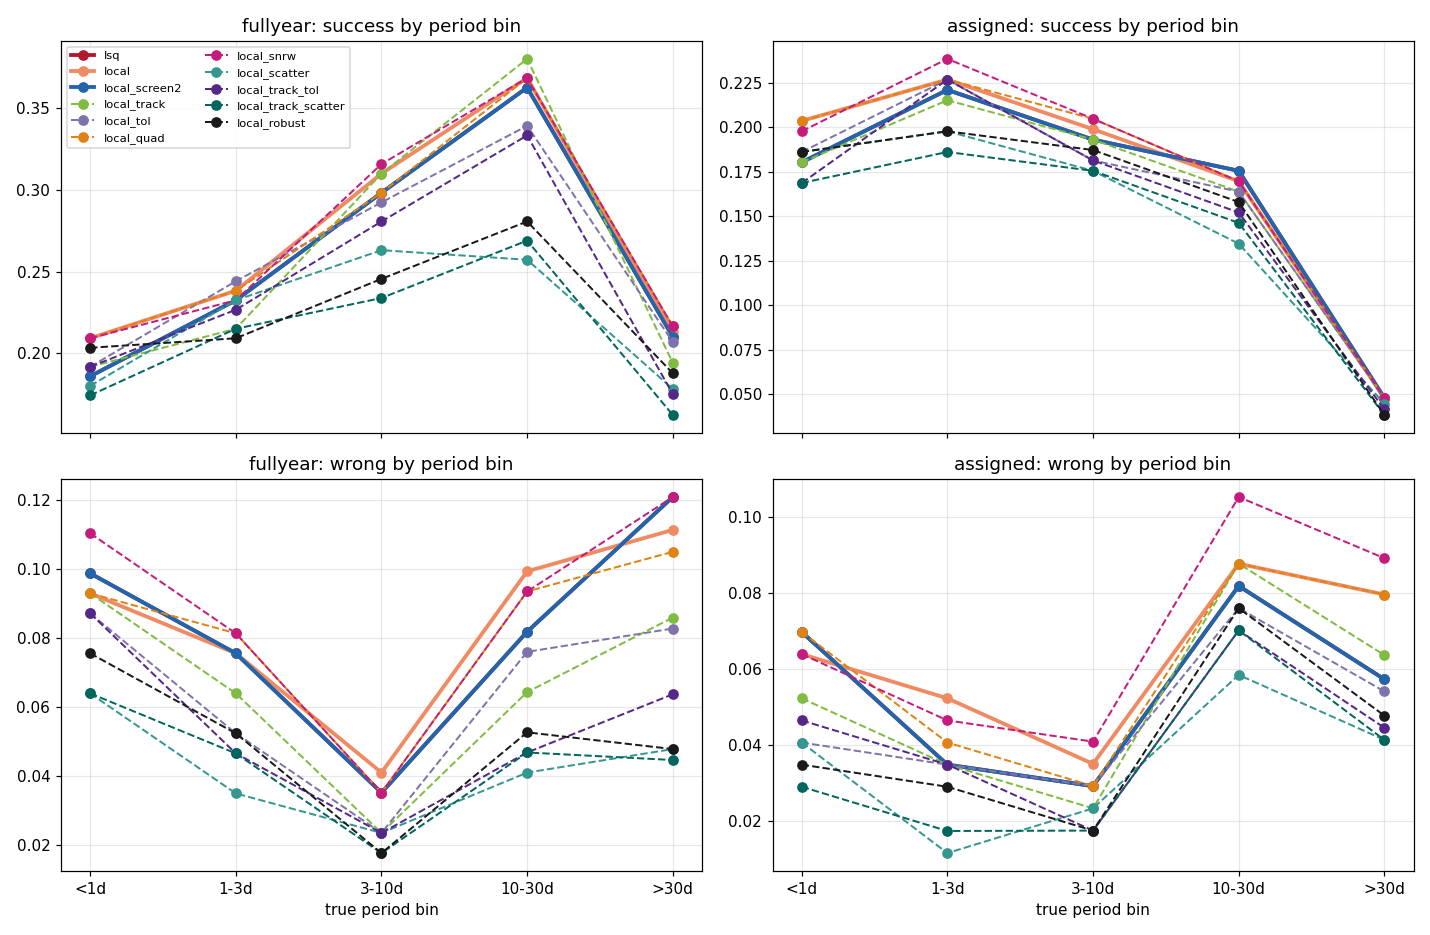

In [4]:
per_star = A.load_per_star()
A.fig_by_bin(per_star, [v for v in A.REFS + A.NEW if (v, 'fullyear') in per_star])
display(Image(str(A.FIG / 'fig_by_bin.png')))

## Gate statistics (candidate level), scatter threshold curve, drift coefficient

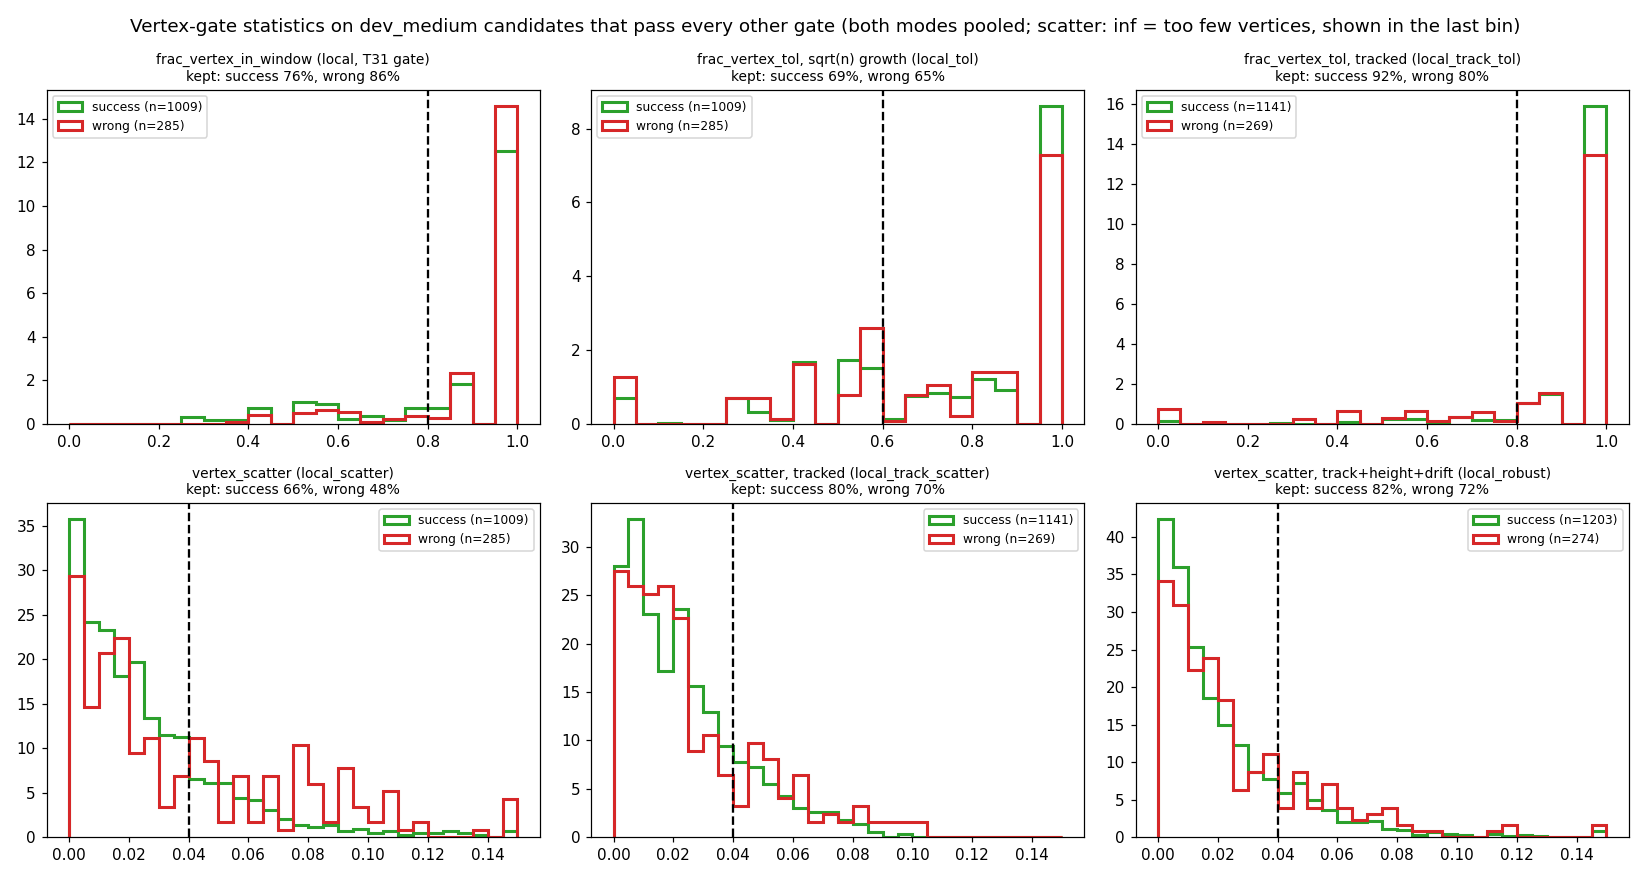

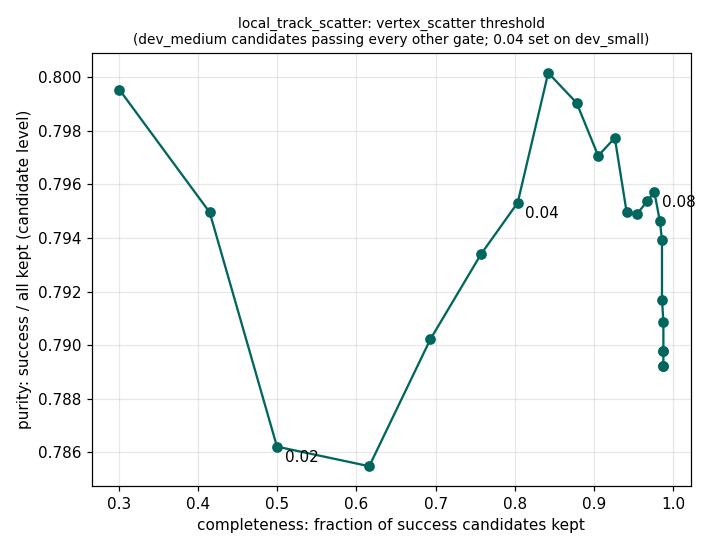

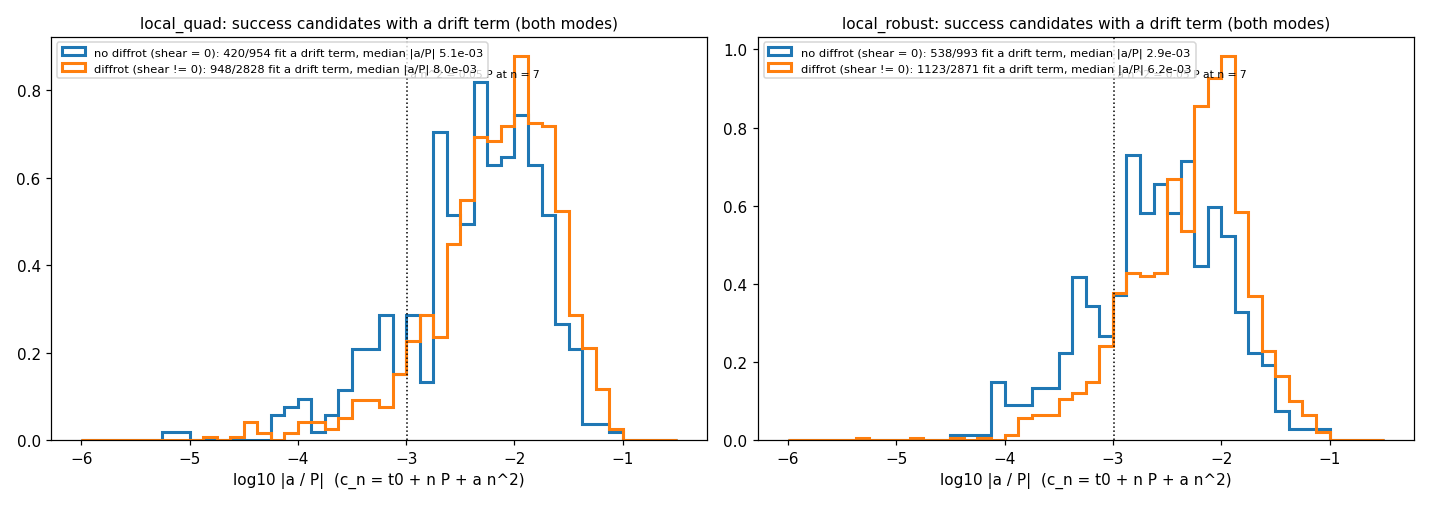

,variant,stat,threshold,op,n_success,n_wrong,kept_success,kept_wrong,n_inf
0,local,v_frac_vertex_in_window,0.80,>=,1009,285,0.755,0.860,0
1,local_tol,v_frac_vertex_tol,0.60,>=,1009,285,0.691,0.653,0
2,local_track_tol,v_frac_vertex_tol,0.80,>=,1141,269,0.924,0.803,0
3,local_scatter,vertex_scatter,0.04,<=,1009,285,0.663,0.481,216
4,local_track_scatter,vertex_scatter,0.04,<=,1141,269,0.804,0.703,38
5,local_robust,vertex_scatter,0.04,<=,1203,274,0.820,0.715,37


,variant,group,n,n_drift_fit,median_abs,q90_abs
0,local_quad,no diffrot (shear = 0),954,420,0.005102,0.020854
1,local_quad,diffrot (shear != 0),2828,948,0.008004,0.028512
2,local_robust,no diffrot (shear = 0),993,538,0.002938,0.014567
3,local_robust,diffrot (shear != 0),2871,1123,0.006189,0.019880


In [5]:
c = pd.read_csv(A.DATA / 'cands_subset.csv.gz')
A.fig_gate_stats(c); A.fig_scatter_curve(c); A.fig_drift_a(c)
for f in ['fig_gate_stats', 'fig_scatter_threshold_curve', 'fig_drift_a']:
    display(Image(str(A.FIG / f'{f}.png')))
display(pd.read_csv(A.DATA / 'gate_stats.csv').round(3)); display(pd.read_csv(A.DATA / 'drift_a_summary.csv'))

## Gained and lost stars: `local_tol` vs `local_screen2`

mode      change
assigned  gained     7
          lost       9
          other     20
fullyear  gained    18
          lost      21
          other     34
dtype: int64

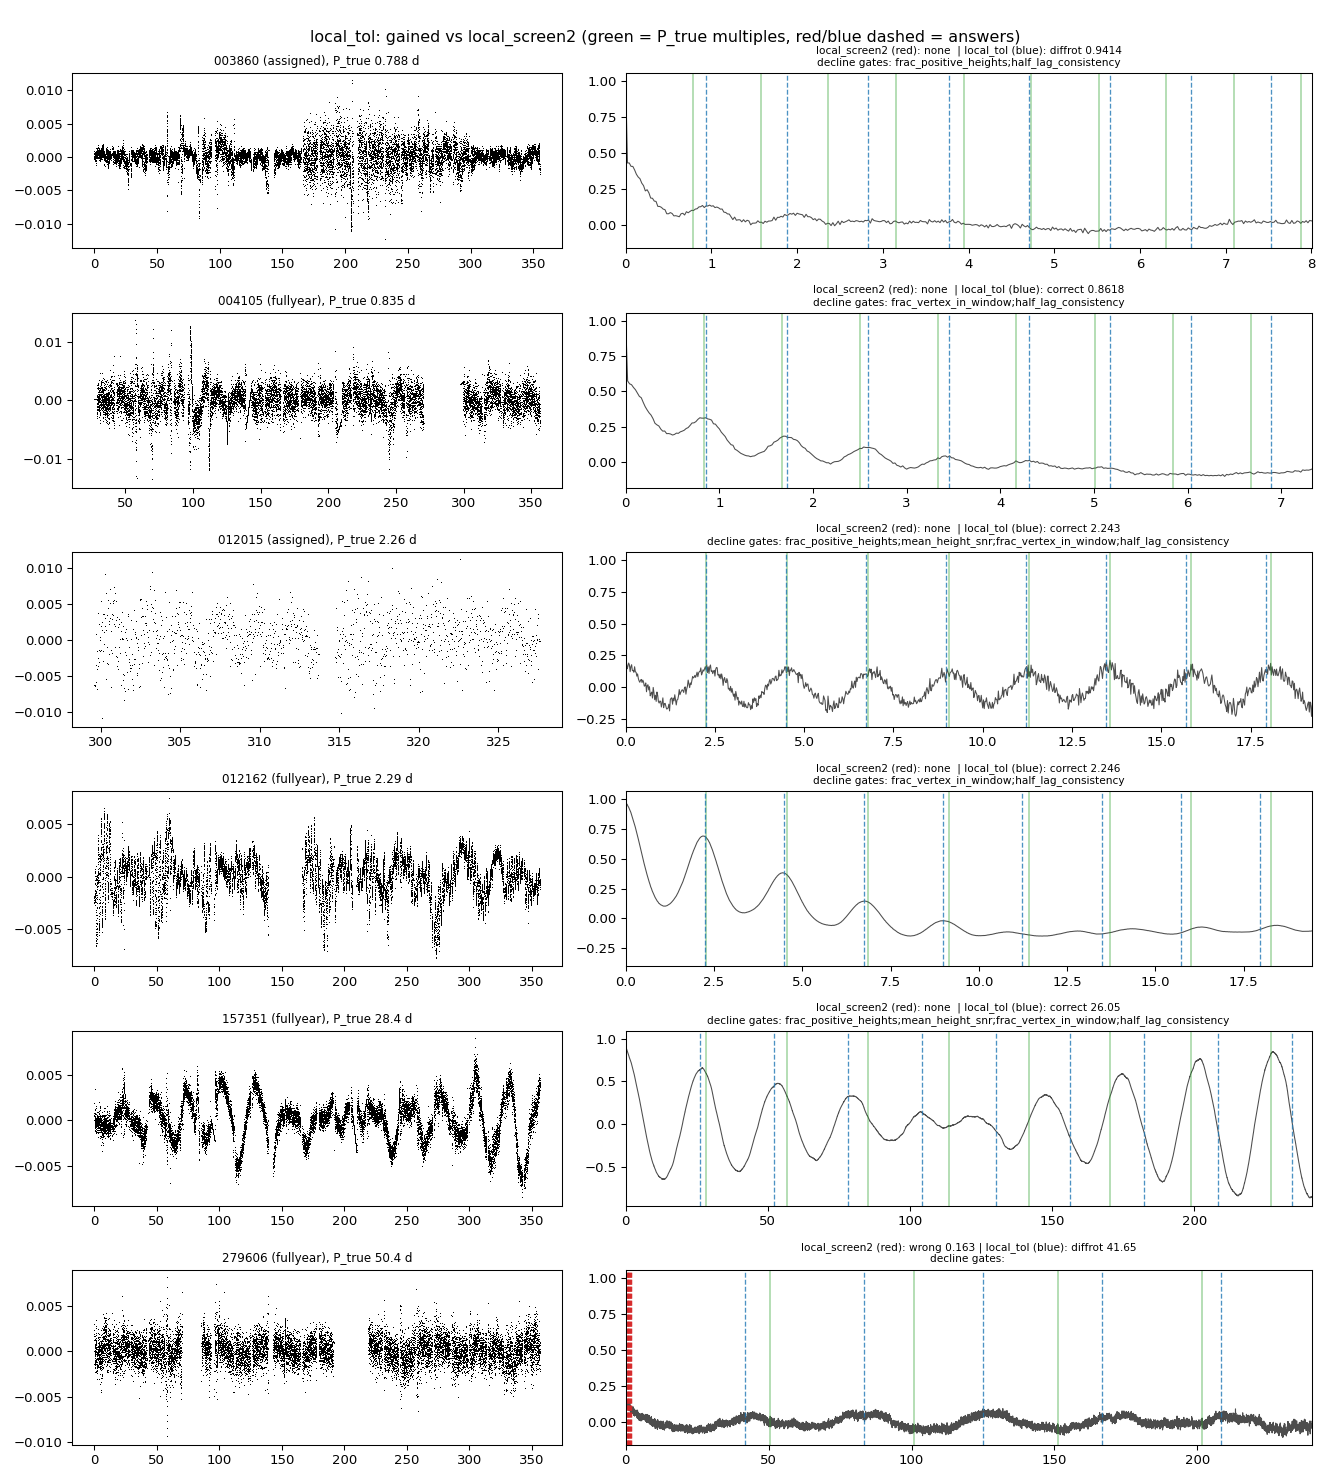

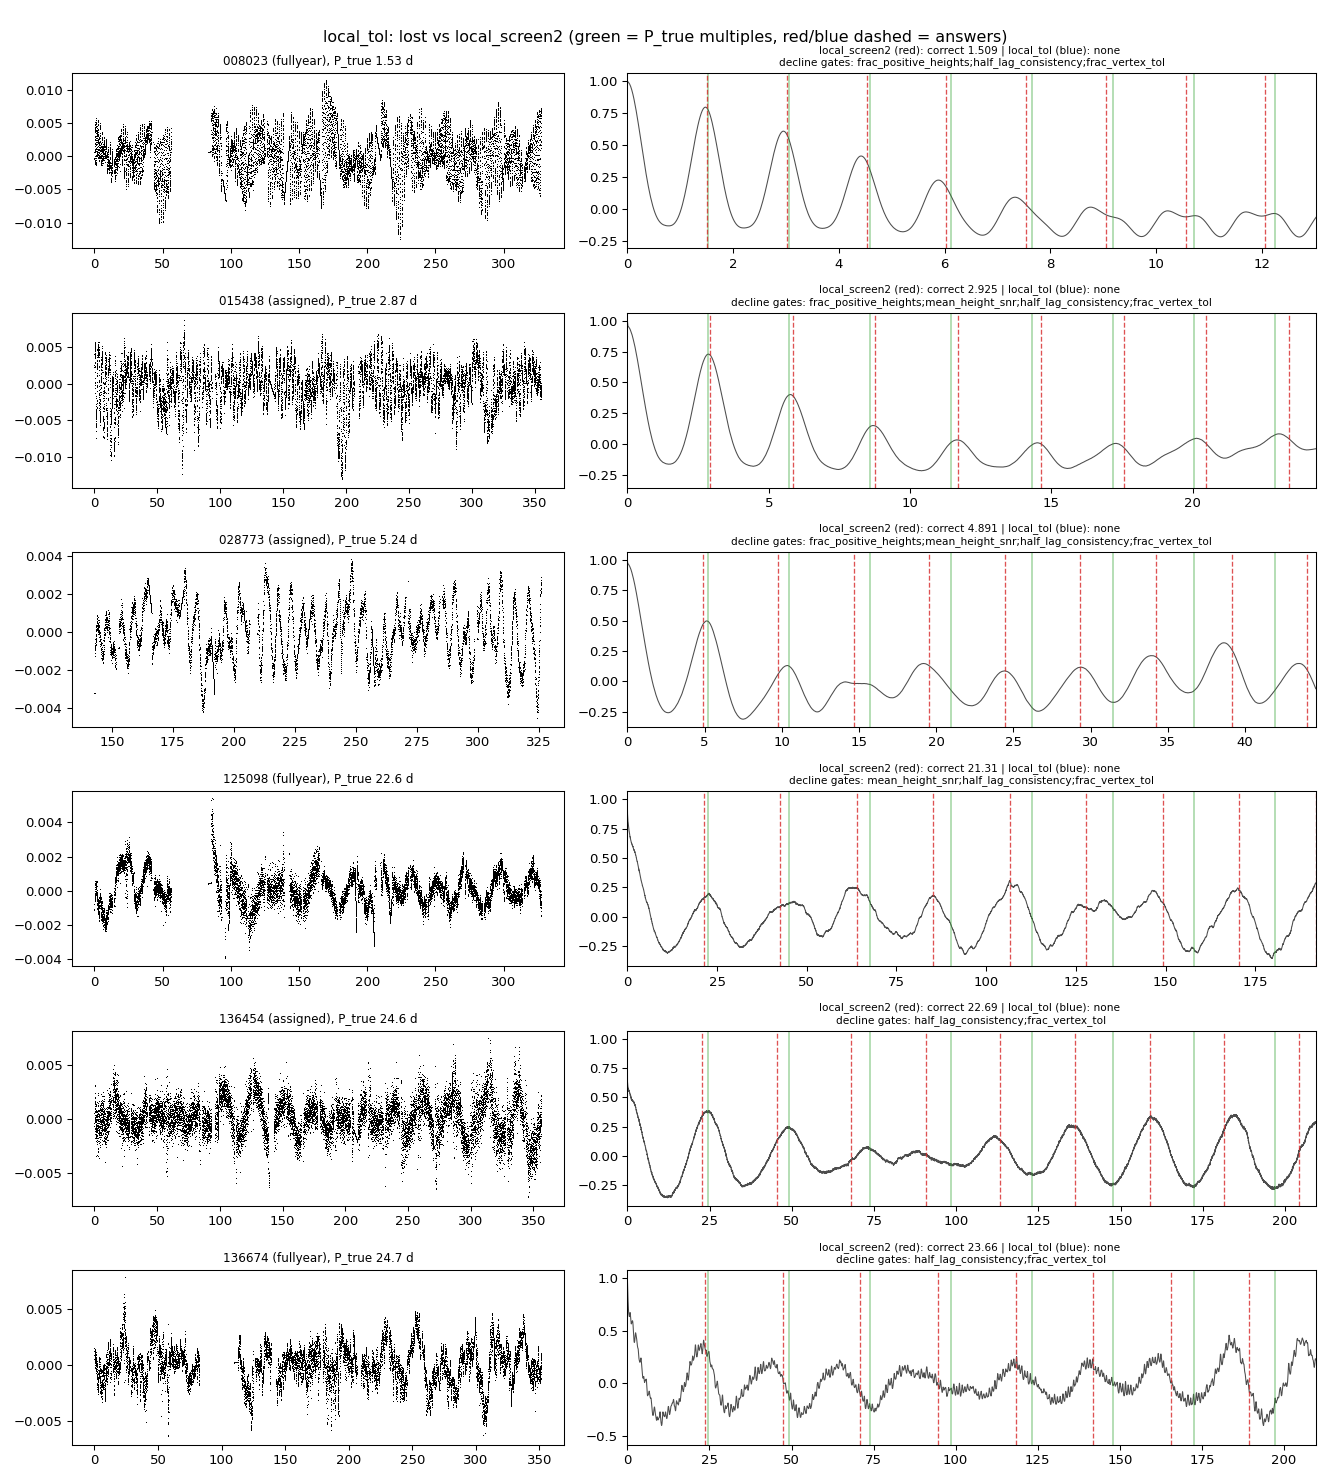

In [6]:
ch = A.changed_stars(per_star, 'local_tol')
display(ch.groupby(['mode','change']).size())
A.fig_examples(ch, 'local_tol', 'gained'); A.fig_examples(ch, 'local_tol', 'lost')
display(Image(str(A.FIG / 'fig_examples_local_tol_gained.png'))); display(Image(str(A.FIG / 'fig_examples_local_tol_lost.png')))